<a href="https://colab.research.google.com/github/Azif-alii/Assessment_of_Supervised_learning/blob/main/Assessment_of_Supervised_learning_Azifali_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1.Data understanding and exploratory analysis**

Load the CSV and inspect its shape, column names, data types and first few records.

In [ ]:
import numpy as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#First Few Rows
df = pd.read_csv('/content/drive/MyDrive/DSA ICT/class activity/bank_marketing_assessment_dataset.csv')
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [ ]:
#column names
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [ ]:
#datatypes
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [ ]:
#shapes
df.shape

(600, 14)

identify missing values and check for duplicate rows.

In [ ]:
 df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [78]:
df.duplicated().sum()

np.int64(0)

 Report the target-class distribution and at least two useful observations from the data. Use suitable visualisations.

In [80]:
# 1. Target Class Distribution
print("Target Class Distribution (Percentage):")
print(df['subscribed'].value_counts(normalize=True) * 100)

Target Class Distribution (Percentage):
subscribed
no     71.0
yes    29.0
Name: proportion, dtype: float64


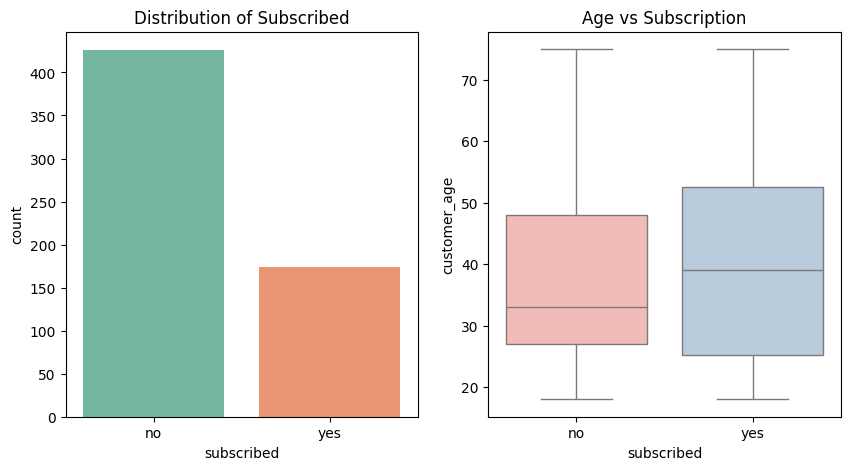

In [77]:
# Set up a simple plot
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.countplot(data=df, x='subscribed', ax=axes[0],hue = 'subscribed',palette='Set2')
axes[0].set_title('Distribution of Subscribed')
sns.boxplot(data=df, x='subscribed', y='customer_age', ax=axes[1], hue = 'subscribed' ,palette='Pastel1')
axes[1].set_title('Age vs Subscription')
plt.show()

# 2. Data preparation and feature engineering

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separate input features (X) and target (y)
X = df.drop(columns=['subscribed'])
y = df['subscribed'].map({'no': 0, 'yes': 1})

In [ ]:
# 2. Split data into training and test sets (80:20 split, stratified, random state fixed)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (480, 13)
Test set shape: (120, 13)


**1.Identify and Handle Missing Values**

We will impute missing values using median for numerical features and the most frequent value (mode) for categorical features. Fitting is strictly done on the training set to prevent leakage.

In [ ]:
from sklearn.impute import SimpleImputer
import pandas as pd

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# Handle numerical missing values (using median)
num_imputer = SimpleImputer(strategy='median')
X_train_num_imputed = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_test_num_imputed = pd.DataFrame(num_imputer.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

# Handle categorical missing values (using mode)
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train_cat_imputed = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
X_test_cat_imputed = pd.DataFrame(cat_imputer.transform(X_test[cat_cols]), columns=cat_cols, index=X_test.index)

print("Missing values handled successfully.")

Missing values handled successfully.


**2.Scale Numerical Features**

We will apply standard scaling to scale all numerical columns to have a mean of 0 and variance of 1.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Fit scaler strictly on imputed training numerical data
scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num_imputed), columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num_imputed), columns=num_cols, index=X_test.index)

print("Numerical features scaled successfully.")

Numerical features scaled successfully.


**3.Encode Categorical Features**

We will apply One-Hot Encoding to convert categorical columns to numerical values.

In [27]:
from sklearn.preprocessing import OneHotEncoder

# Fit One-Hot Encoder strictly on imputed training categorical data
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat_encoded_raw = encoder.fit_transform(X_train_cat_imputed)
X_test_cat_encoded_raw = encoder.transform(X_test_cat_imputed)

# Get feature names for mapping back to dataframe
encoded_cols = encoder.get_feature_names_out(cat_cols)
X_train_cat_encoded = pd.DataFrame(X_train_cat_encoded_raw, columns=encoded_cols, index=X_train.index)
X_test_cat_encoded = pd.DataFrame(X_test_cat_encoded_raw, columns=encoded_cols, index=X_test.index)

print("Categorical features encoded successfully.")

Categorical features encoded successfully.


**4.Combine Preprocessed Features**

Finally, we concatenate the scaled numerical features and encoded categorical features into a single array ready for modeling.

In [51]:
# Combine numerical and categorical datasets together
X_train_final = pd.concat([X_train_num_scaled, X_train_cat_encoded], axis=1)
X_test_final = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis=1)

# Keep numpy versions for algorithms compatibility
X_train_preprocessed = X_train_final.values
X_test_preprocessed = X_test_final.values

print(f"Final training shape: {X_train_final.shape}")
print(f"Final test shape: {X_test_final.shape}")

Final training shape: (480, 31)
Final test shape: (120, 31)


Ensure preprocessing is fitted only on the training data; avoid data leakage

In [28]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

# Group features by type
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# Create simple pipelines for both feature types
preprocessor = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols)
)

# Fit on training data and transform both to prevent data leakage
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("Preprocessing completed successfully without data leakage.")

Preprocessing completed successfully without data leakage.


# **3. Model building**

**Build a Logistic Regression classification model**

In [41]:
# Importing linear regresssion model
from sklearn.linear_model import LinearRegression

In [42]:
# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_preprocessed, y_train)

print("Logistic Regression model successfully trained.")

Logistic Regression model successfully trained.


**Build a Decision Tree or Random Forest classification model.**

In [43]:
#importing decision tree
from sklearn.tree import DecisionTreeClassifier

In [44]:
# Initialize and train the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_classifier.fit(X_train_preprocessed, y_train)

print("Decision Tree Classifier successfully trained.")

Decision Tree Classifier successfully trained.


## **4. Model evaluation and comparison**





**Evaluate both models on the test set using accuracy, precision, recall and F1-score**

In [45]:
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import accuracy_score, f1_score

In [46]:
print("Logistic Regression:")
print("Accuracy Score:",accuracy_score(y_test, log_reg.predict(X_test_preprocessed)))
print("Precision Score:",precision_score(y_test, log_reg.predict(X_test_preprocessed)))
print("Recall Score:",recall_score(y_test, log_reg.predict(X_test_preprocessed)))
print("F1 Score",f1_score(y_test, log_reg.predict(X_test_preprocessed)))

Logistic Regression:
Accuracy Score: 0.85
Precision Score: 0.8695652173913043
Recall Score: 0.5714285714285714
F1 Score 0.6896551724137931


In [47]:
print("Decision Tree Classifier:")
print("Accuracy Score:",accuracy_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("Precision Score:",precision_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("Recall Score:",recall_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("F1 Score",f1_score(y_test, dt_classifier.predict(X_test_preprocessed)))

Decision Tree Classifier:
Accuracy Score: 0.8666666666666667
Precision Score: 0.8518518518518519
Recall Score: 0.6571428571428571
F1 Score 0.7419354838709677


G**enerate and interpret a confusion matrix for each model**

In [48]:
from sklearn.metrics import confusion_matrix

In [49]:
print("Logistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, log_reg.predict(X_test_preprocessed)))

Logistic Regression Confusion Matrix:
[[82  3]
 [15 20]]


In [50]:
print("Decision Tree Classifier Confusion Matrix:")
print(confusion_matrix(y_test, dt_classifier.predict(X_test_preprocessed)))

Decision Tree Classifier Confusion Matrix:
[[81  4]
 [12 23]]


**Compare the models and explain which one you would recommend for this business problem.**


**Recommendation: The Decision Tree Classifier is recommended.**

Higher Recall: The Decision Tree correctly identified 23 out of 35 actual subscribers, whereas Logistic Regression only captured 20. This means using the Decision Tree model avoids missing 3 additional likely subscribers (reducing False Negatives from 15 to 12). Better Overall Balance (F1-Score of 74.19% vs 68.97%): The Decision Tree achieves a significantly better F1-Score while maintaining an overall test accuracy of 86.67%.

## **5. Business interpretation and prediction**

 **the most influential features using a suitable model interpretation method**

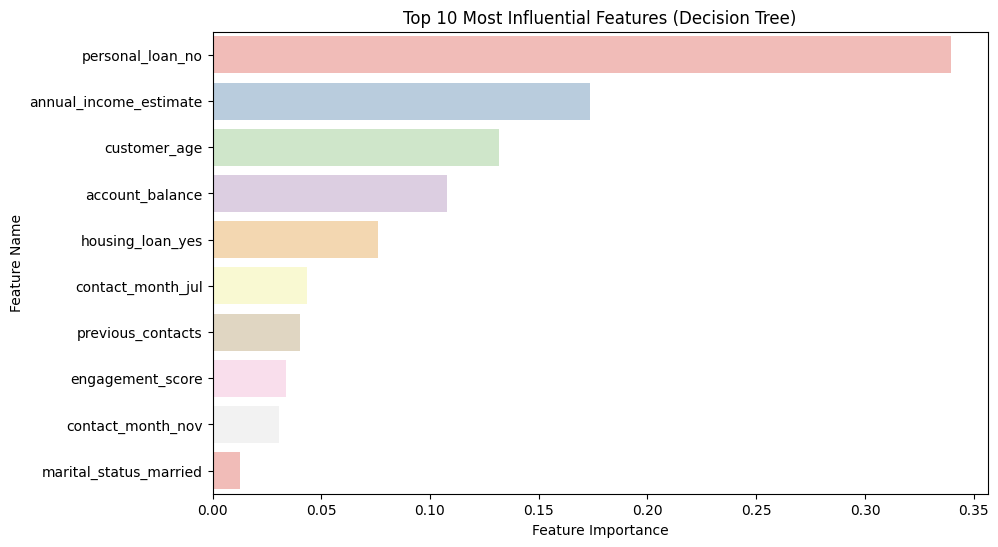

In [79]:
# Extract feature importances
feature_names = num_cols.tolist() + encoded_cols.tolist()
importances = dt_classifier.feature_importances_

# Create a DataFrame for easy viewing
feature_importance_df = pd.DataFrame({'Feature': feature_names,'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plot top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature',hue = 'Feature',palette='Pastel1')
plt.title('Top 10 Most Influential Features (Decision Tree)')
plt.xlabel('Feature Importance')
plt.ylabel('Feature Name')
plt.show()

**• Explain the limitations of the interpretation**
1. **Correlation vs. Causation:** High feature importance indicates that a feature is useful for splitting the nodes in this specific tree structure; it does not guarantee a direct causal relationship.
2. **Instability (High Variance):** Decision Trees are sensitive to slight variations in training data. A small change in the dataset can lead to a completely different tree layout and altered feature importances.
3. **Bias toward high cardinality:** Trees naturally favor features with many unique values or categories, as they offer more options for split points.

**• Predictions on Sample Customers**

#####Use the selected model to predict subscription for five sample customers from the test set. Display the predicted class and, if available, probability.

We will select 5 random sample customers from our test set and output their actual subscription values alongside our model's predictions and predicted probabilities.

In [62]:
# Select 5 sample indices from test data
sample_indices = X_test.index[:5]

# Get preprocessed sample features
samples_preprocessed = X_test_preprocessed[:5]

# Make predictions
predicted_classes = dt_classifier.predict(samples_preprocessed)
predicted_probabilities = dt_classifier.predict_proba(samples_preprocessed)[:, 1]

# Create a display DataFrame
samples_df = X_test.loc[sample_indices].copy()
samples_df['Actual Subscribed'] = y_test.loc[sample_indices].map({0: 'no', 1: 'yes'})
samples_df['Predicted Class'] = ['yes' if p == 1 else 'no' for p in predicted_classes]
samples_df['Probability of Yes'] = predicted_probabilities

display(samples_df[['customer_age', 'job', 'Actual Subscribed', 'Predicted Class', 'Probability of Yes']])

,customer_age,job,Actual Subscribed,Predicted Class,Probability of Yes
269,54,blue-collar,no,no,0.000000
70,18,admin,yes,yes,1.000000
376,57,management,yes,no,0.036199
543,64,services,yes,yes,1.000000
429,23,admin,no,no,0.036199


**Business Conclusion**

To optimize our marketing strategy for term deposit subscriptions, we evaluated a Logistic Regression and a Decision Tree Classifier. The Decision Tree Classifier is recommended because it achieved a superior recall of 65.71% (capturing 23 out of 35 actual subscribers) and a higher F1-score of 74.19%, effectively minimizing the costly error of missing potential subscribers. To improve performance further in future iterations, we would explore ensemble methods such as Random Forests or XGBoost to decrease variance and try balancing techniques like SMOTE to address the inherent class imbalance of the dataset.